# Apply bias adjustment to climate projection data

Every climate model shows a deviation from climatology, called bias. The procedure to correct or limit this error is called Bias Adjustment (BA).

Period 1950-1993 is used for training the model on ERA5, period 1994-2023 is used to test the model on the historical experiment of NEX-GDDP-CMIP6, then the adjustment is applied to scenario experiments for period 2024-2100.
A q-q plot is made to test the performance of the BA against the test set.

A variation of Quantile Mapping (QM) approach is used, i.e. the Quantile Delta Mapping (QDM) algorithm, and it is applied to variables derived from `tas` and `pr`. In particular, `tasmax` and the Diurnal Temperature Range (DTR) are bias adjusted, then `tasmin` is derived by subtracting the adjusted DTR from the adjusted `tasmax`, to [avoid non-physical values](https://doi.org/10.5194/hess-16-3309-2012) introduced by the adjustment.
This method should ensure physical values because DTR quantiles are always mapped between positive values.

## Negative DTR values

After some tests, negative values of DTR seem to appear from the adjustment. This should not be possible with QM, since only positive quantiles are available for the mapping and values which lay outside the support of the cumulative frequency distribution of historical or reference data are extrapolated to the nearest quantiles (i.e. quantile 0 for values lower than the minimum and quantile 1 for values greater than the maximum).

With QDM the issue may be clearer to address, since the algorithm uses QM on data after having performed some operations on it. First, the difference between the projected value and the historical value corresponding to the same quantile is calculated, i.e. the "delta". Then QM is applied to projected values and corresponding deltas are added to the results, to conserve the model trend of projected data with respect to historical data. Again, extrapolation is applied if needed.

Since QM is theoretically excluded as the cause of the problem, in QDM the process to evaluate and add the delta could be the cause of the problem. It is so if, using the nomenclature of 2015CannonBiasAdjustment and the fact that cumulative probability distributions are monotone,

$$
    \hat{x}_{m,p}(t) < 0 \iff \Delta_m(t) < -\hat{x}_{o:m,h:p} \leq 0 \iff \\
    \iff x_{m,p}(t) + \hat{x}_{o:m,h:p} < F_{m,h}^{-1}[\tau_{m,p}(t)] \iff F_{m,h}[x_{m,p}(t) + \hat{x}_{o:m,h:p}] < F_{m,p}^{(t)}[x_{m,p}(t)]
$$

since $\hat{x}_{o:m,h:p} = F_{o,h}^{-1}[\tau_{m,p}(t)] \geq 0$ because is the result of QM.
This condition can occur physically, even if it is not frequent (no further studies are made in this thesis).

In reality, even applying QM to the actual data, these issue appears for the same data points affected in QDM. Hence there might be a bug in the code provided by third parties, e.g. when extrapolation is performed, but is has not been identified yet.
To circumvent the problem while waiting for a more robust solution, the absolute value of the adjusted DTR is taken to ensure physical `tasmin` adjusted values. Similarly to the solution to the issue in NEX-GDDP-DATA, this corresponds to swap `tasmax` and `tasmin` values of the same day when they present non-physical extremes.

In [1]:
import importlib

import matplotlib.pyplot as plt
import numpy
import xarray
import xclim.sdba

import plots
import settings
import thesis

# Workaround to reload settings if this block is executed a second time but notebook is not restarted.
try:
    id(flag_reload)
    flag_reload = importlib.reload(settings)
except NameError:  # Raised if `flag_reload` is not defined, hence when block is executed the first time.
    flag_reload = settings

In [2]:
nquantiles_training = 51
nquantiles_test = 21

dir_data = settings.dir_data / settings.location / "preprocessed"

dir_out = dir_data.parent / "adjusted"
dir_out.mkdir(parents=True, exist_ok=True)

In [3]:
chunks = {"latitude": 1, "longitude": 1, "time": -1}
ds_reference = xarray.open_dataset(dir_data / "reference.nc", chunks=chunks)

m = "EC-Earth3"  # Only model EC-Earth3 is used for the midterm discussion.

ds_historical = xarray.open_dataset(dir_data / f"historical_{m}.nc", chunks=chunks)

concat_dim = "scenario"
ds_scenario = xarray.open_mfdataset(
    [dir_data / f"{s}_{m}.nc" for s in thesis.scenario],
    chunks=chunks,
    concat_dim=concat_dim,
    combine="nested",
    combine_attrs="drop_conflicts"
)
ds_scenario = ds_scenario.assign_coords({concat_dim: list(thesis.scenario)})

# Collect all datasets in an iterator for programmatic access.
dict_dataset = {"reference": ds_reference, "historical": ds_historical}
dict_dataset.update({s: ds_scenario.loc[{concat_dim: s}].reset_coords(drop=True) for s in thesis.scenario})

# Collect all datasets in a single dataset for convenience in plotting.
e_dim = "experiment"
ds_data = xarray.concat(
    dict_dataset.values(),  # From Python 3.7 dict preserves order.
    e_dim,
    combine_attrs="drop_conflicts"
)
ds_data = ds_data.assign_coords({e_dim: list(dict_dataset.keys())})
ds_data = ds_data.chunk(chunks)

In [4]:
ba = {}  # Store data about the adjustment of selected variables.

## BA of daily temperature

First evaluate DTR and introduce it as new variable to be adjusted.

In [5]:
ds_data = ds_data.assign({
    "DTR": ds_data["tasmax"] - ds_data["tasmin"]
})
ds_data["DTR"].attrs["long_name"] = "Diurnal Temperature Range"

Then plot the time series of daily temperatures.

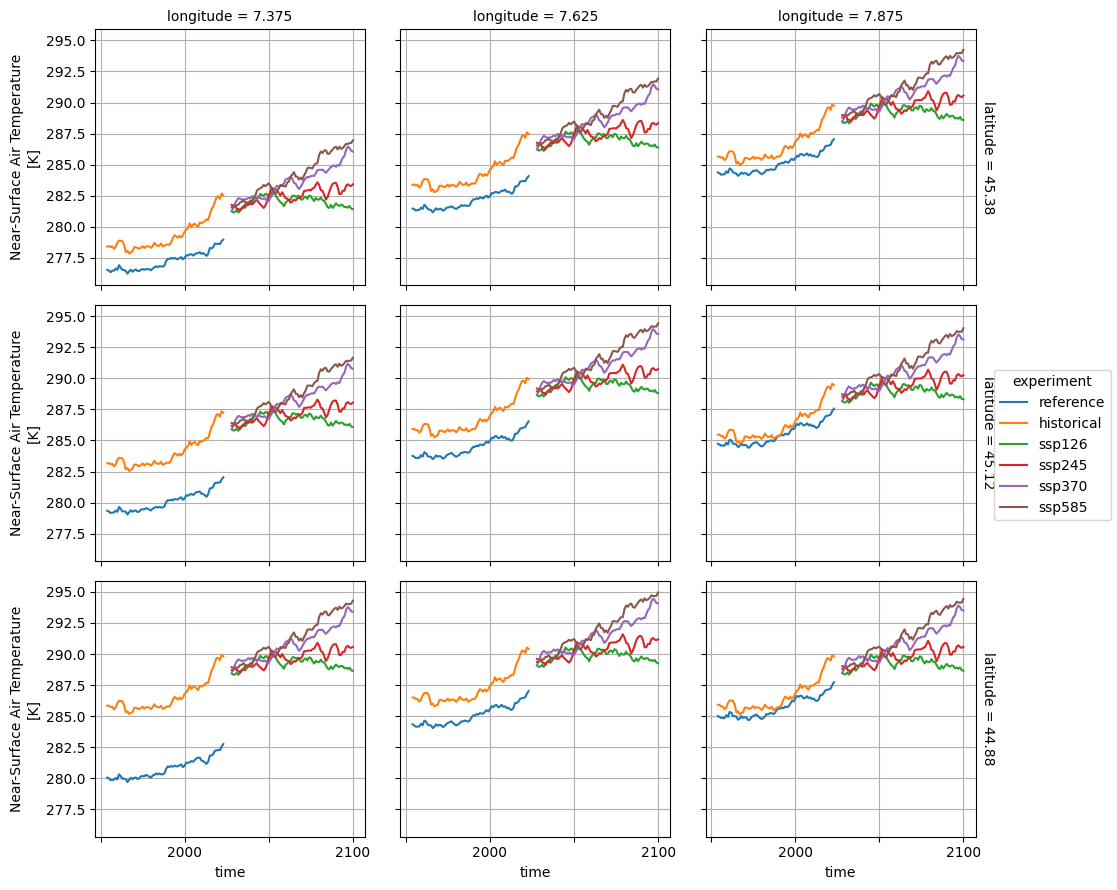

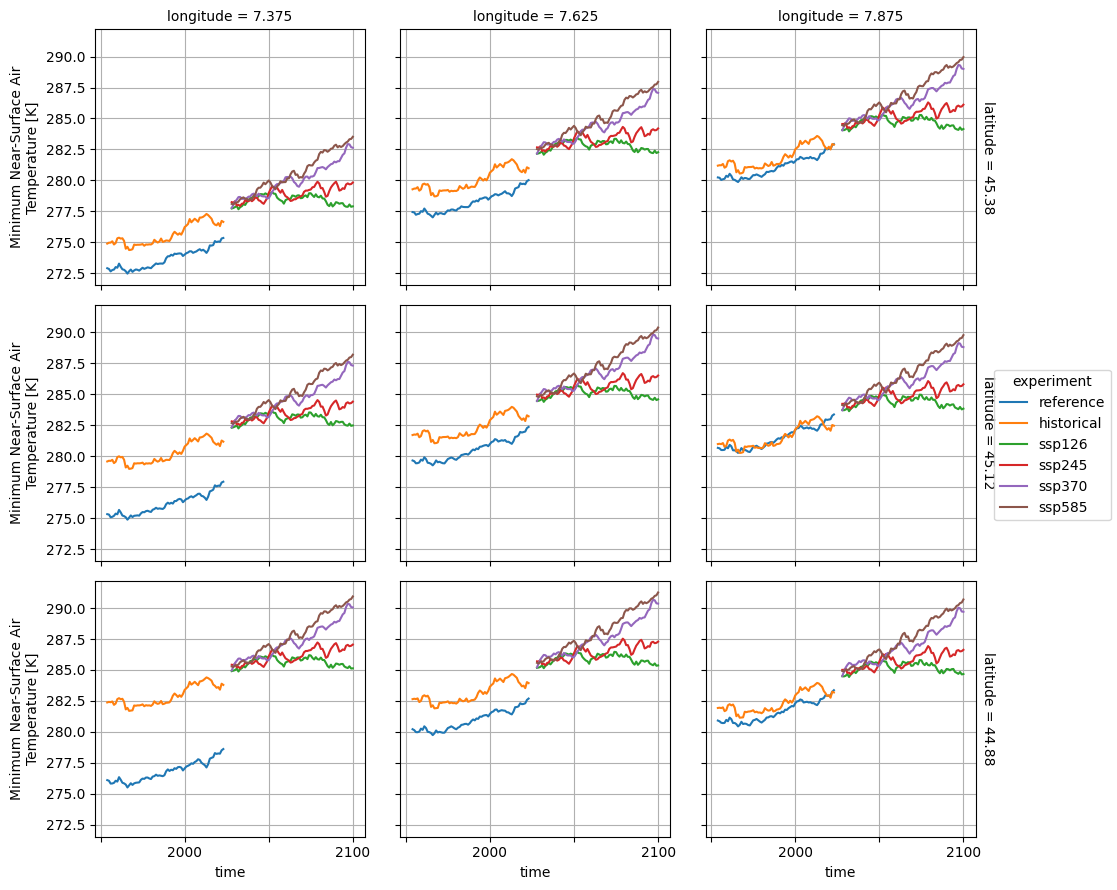

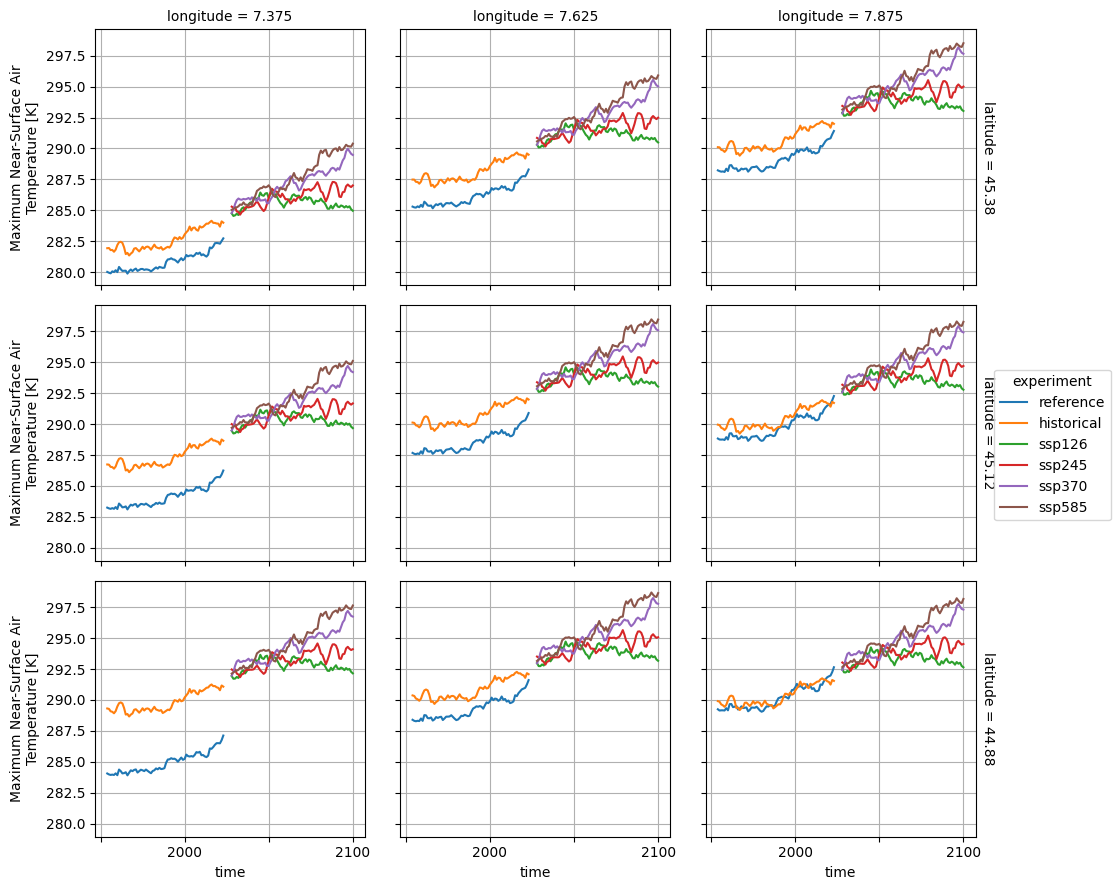

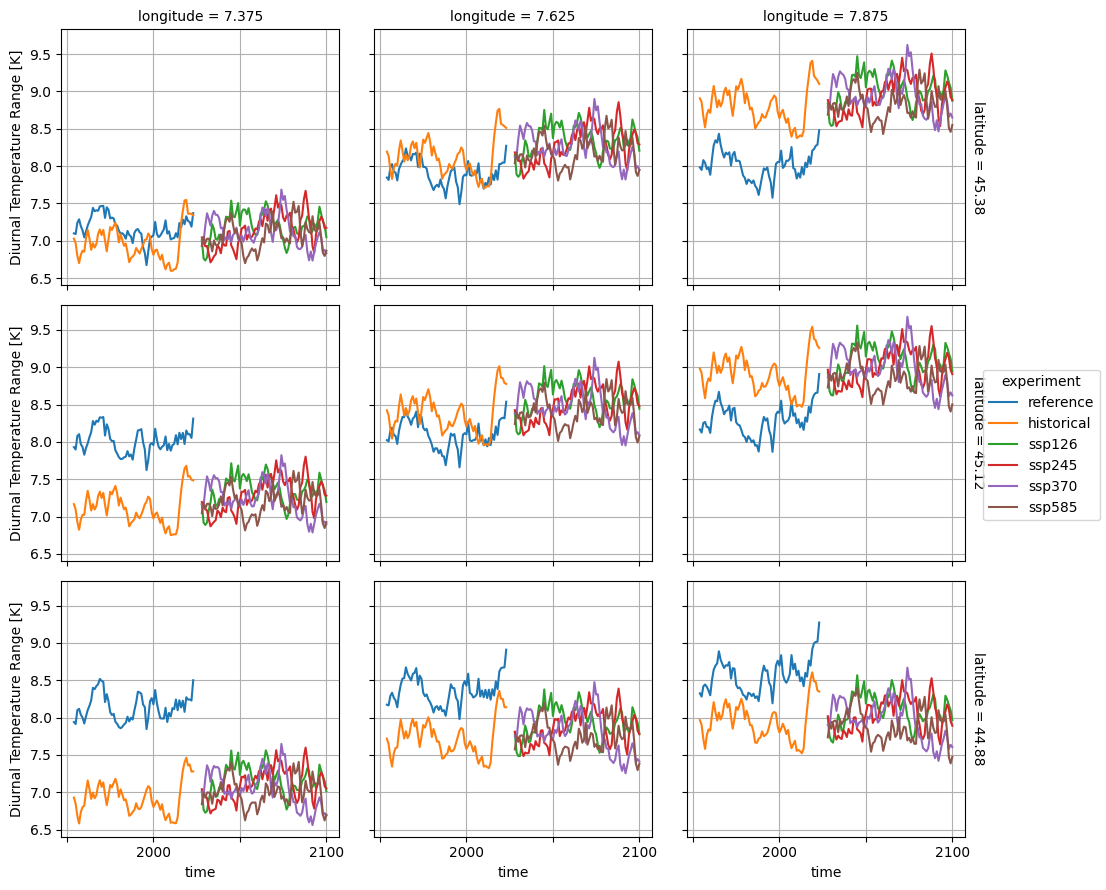

In [6]:
variables = ["tas", "tasmin", "tasmax", "DTR"]
for v in variables:
    plots.yearly_mean_time_series_facet(ds_data[v], hue=e_dim, fname=f"adjusted_{v}_{m}_pre.pdf")

Then apply QDM, it is additive for temperature.

In [7]:
_da = {}
for v in variables:
    ba[v] = xclim.sdba.QuantileDeltaMapping.train(
        ds_data[v].sel({e_dim: "reference", "time": thesis.training_period}, drop=True),
        ds_data[v].sel({e_dim: "historical", "time": thesis.training_period}, drop=True),
        nquantiles=numpy.linspace(0, 1, num=nquantiles_training, endpoint=True),
        group="time",
        kind='+'
    )
    _da[v] = ba[v].adjust(ds_data[v], interp="linear", extrapolation="constant")
    _da[v].name = v  # Overwrite the default name.
ds_adjusted = xarray.Dataset(data_vars=_da, attrs=ds_data.attrs)
ds_adjusted["DTR"] = abs(ds_adjusted["DTR"])  # Same considerations of swapping tasmin and tasmax after BA apply.
ds_adjusted["tasmin"] = ds_adjusted["tasmax"] - ds_adjusted["DTR"]
ds_adjusted["tasmin"].name = "tasmin"
ds_adjusted["tasmin"].attrs = ds_data["tasmin"].attrs

# Insert the original reference, which is correct by definition.
ds_adjusted = ds_adjusted.drop_sel({e_dim: "reference"})
ds_adjusted = xarray.concat(
    (ds_adjusted, ds_data.sel({e_dim: "reference"})),
    e_dim
)

Plot the results of BA for temperature variables.

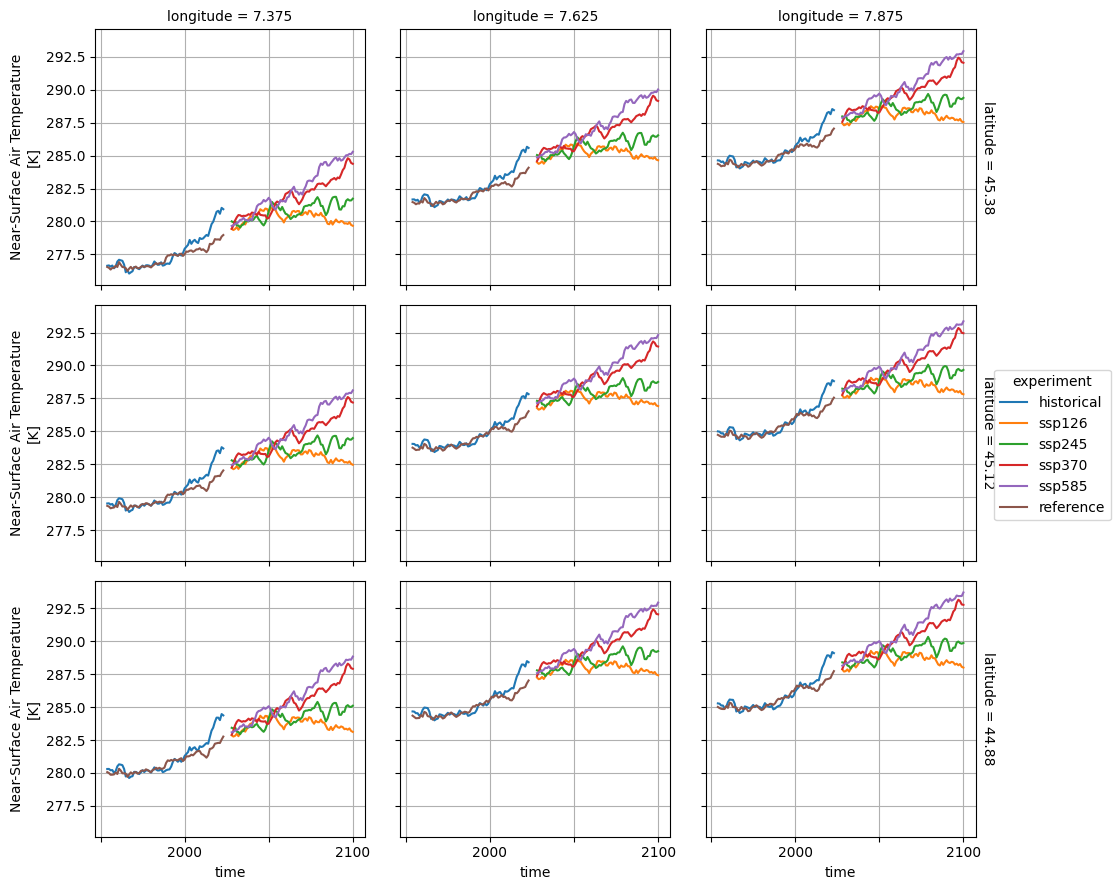

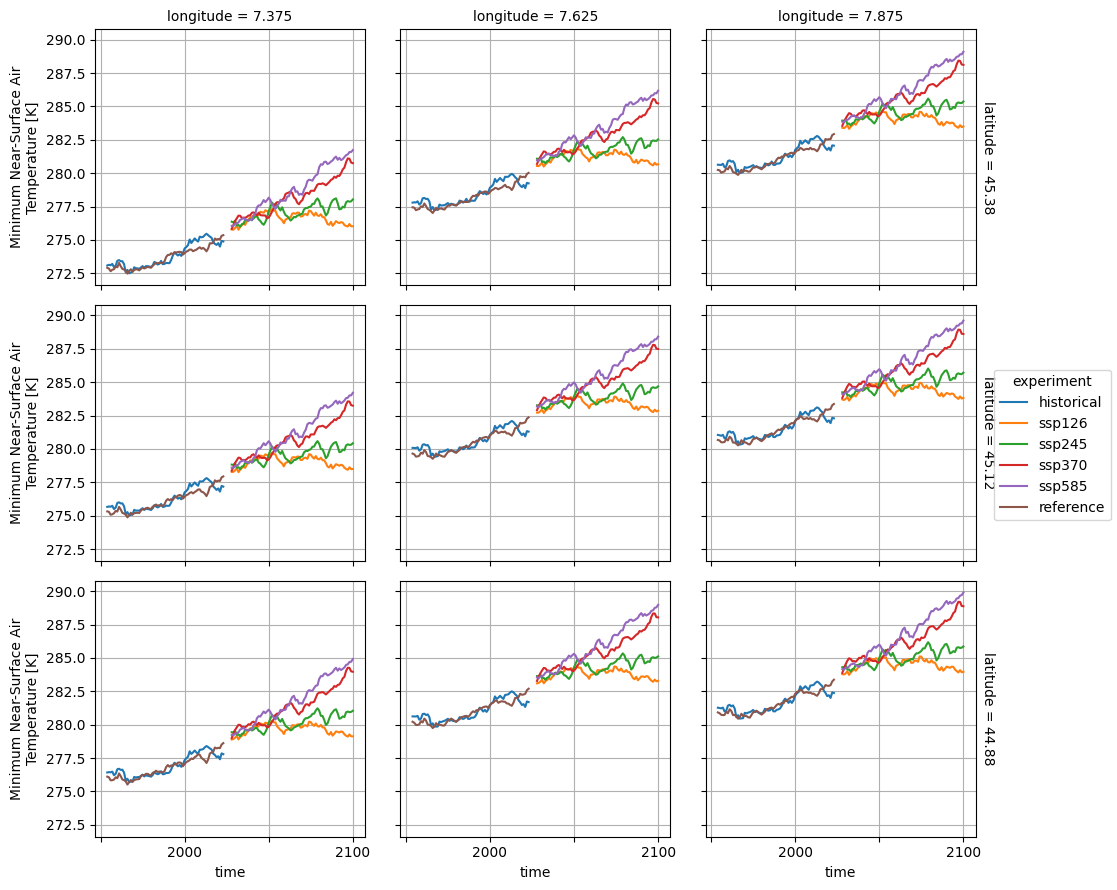

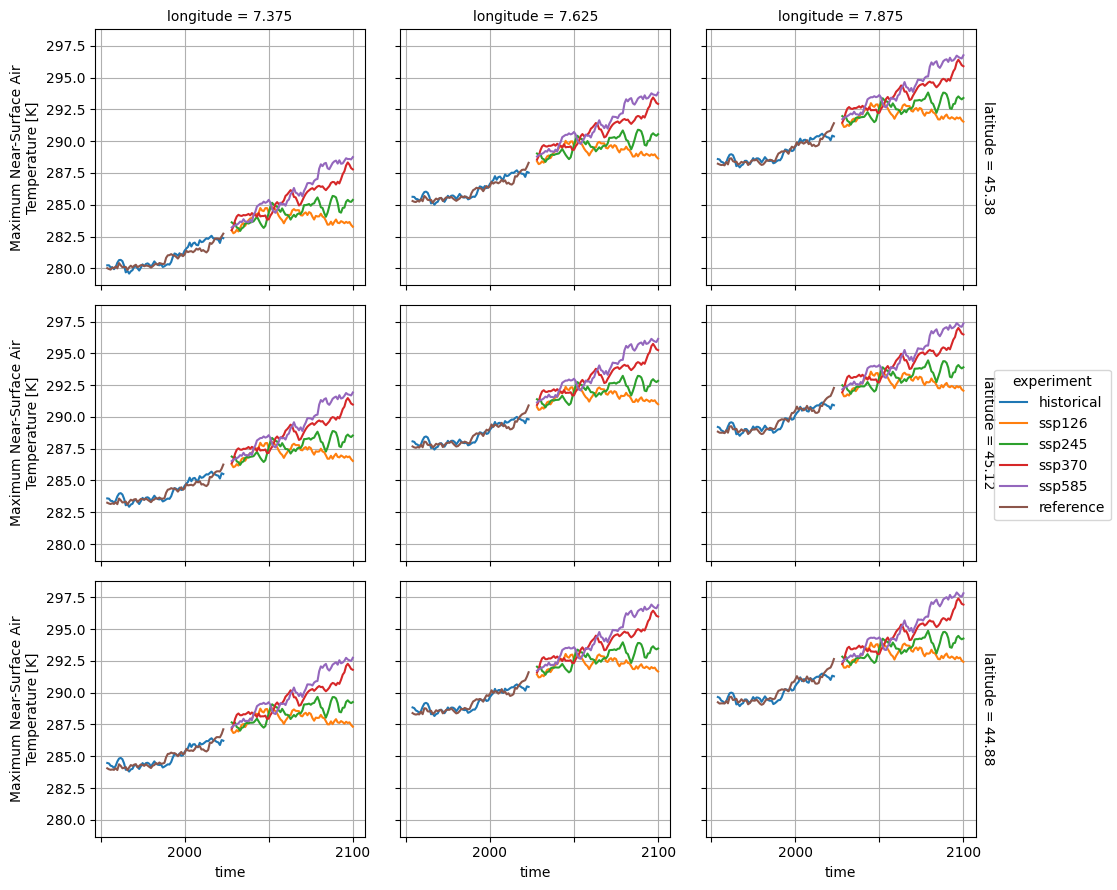

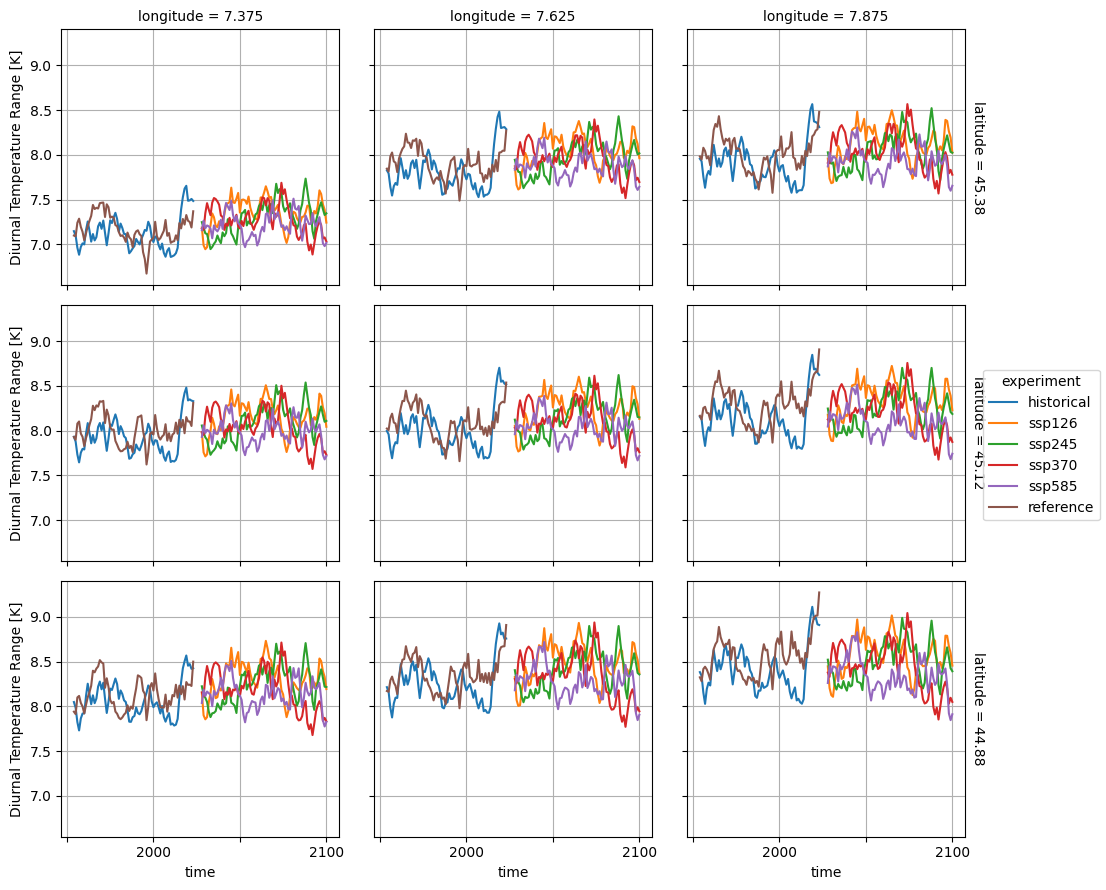

In [8]:
for v in variables:
    plots.yearly_mean_time_series_facet(ds_adjusted[v], hue=e_dim, fname=f"adjusted_{v}_{m}_post.pdf")

Compare pre and post BA time series visually.

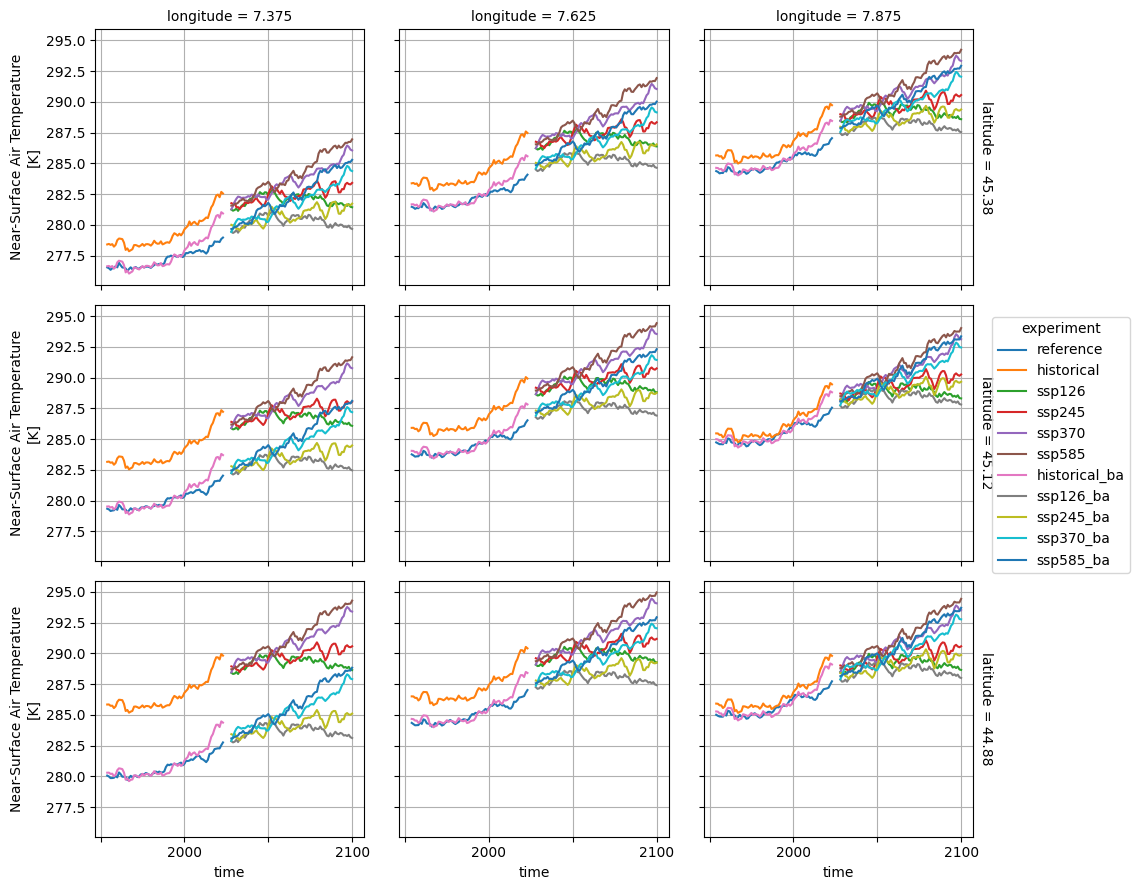

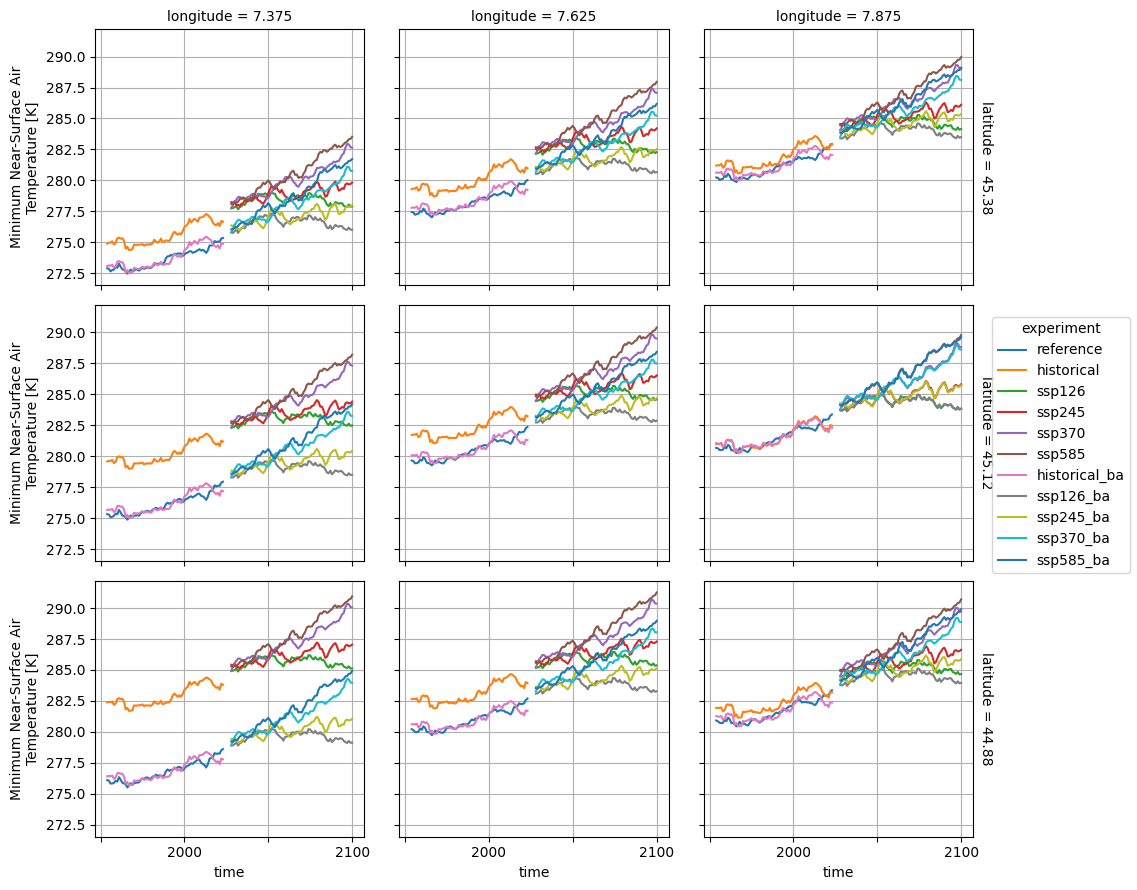

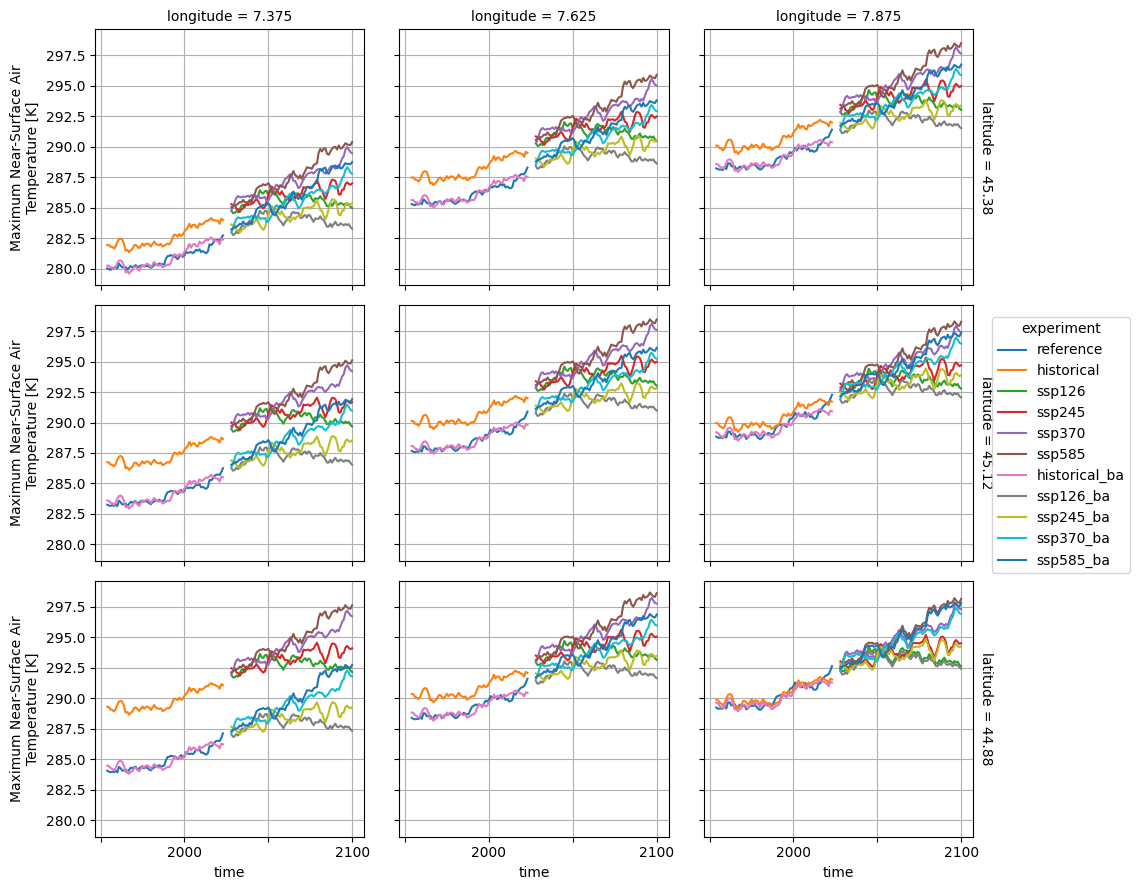

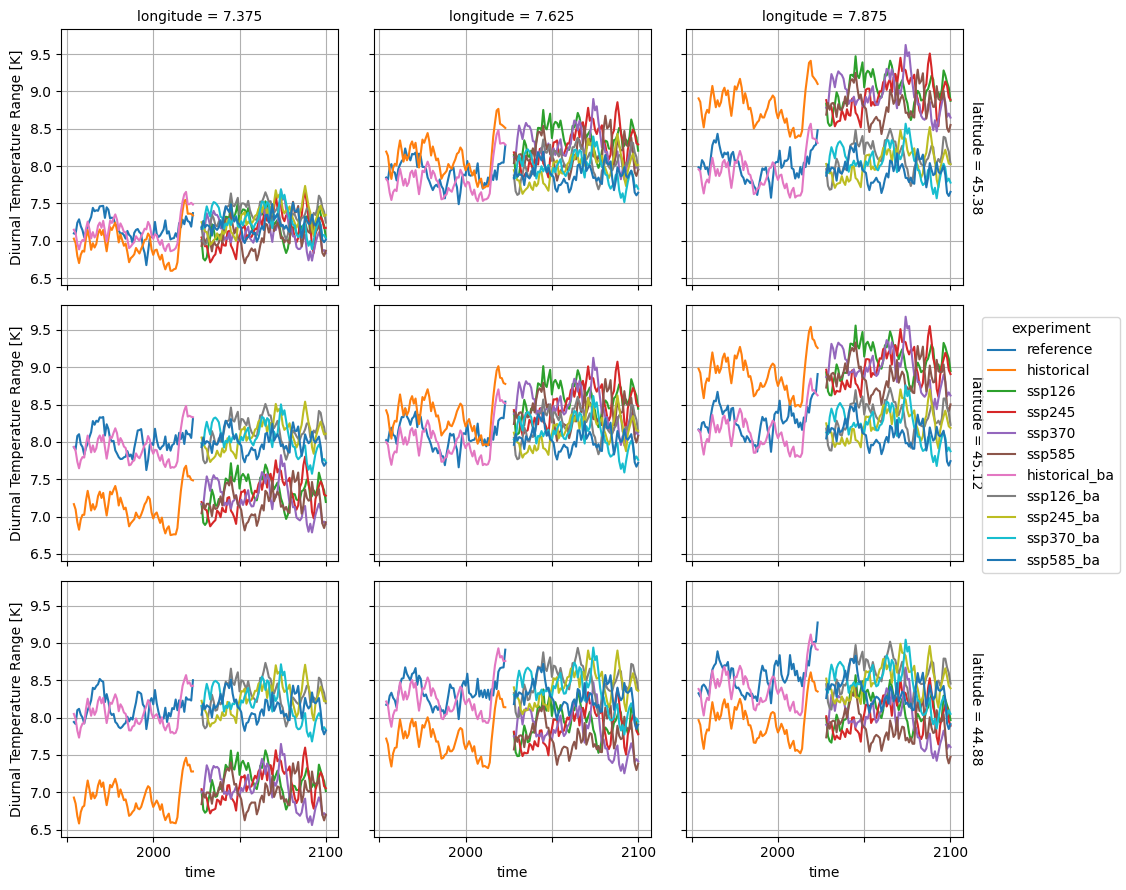

In [9]:
_ds = xarray.concat(
    (ds_data[variables], ds_adjusted[variables].assign_coords({e_dim: ds_adjusted[e_dim].str + "_ba"})),
    e_dim,
    combine_attrs="drop_conflicts"
)
_ds = _ds.drop_sel({e_dim: "reference_ba"})  # Do not plot same time series twice.
for v in variables:
    plots.yearly_mean_time_series_facet(_ds[v], hue=e_dim, fname=f"adjusted_{v}_{m}_prepost.pdf")

## BA of daily precipitation

First plot the time series of daily precipitation.

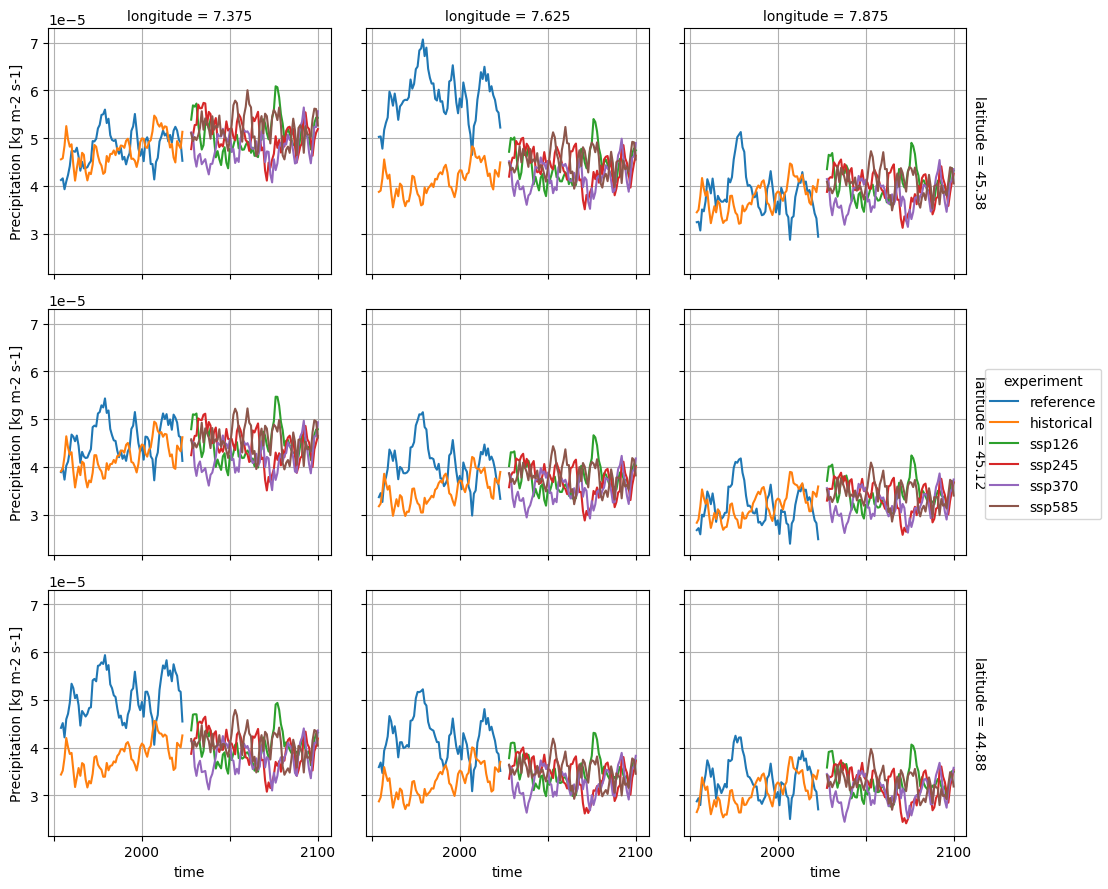

In [10]:
variables = ["pr"]  # Variable tp is present only in ERA5, hence no BA needs to be applied.
for v in variables:
    plots.yearly_mean_time_series_facet(ds_data[v], hue=e_dim, fname=f"adjusted_{v}_{m}_pre.pdf")

Then apply QDM, it is multiplicative for precipitation.
In every dataset are present null values which may be mapped together by QM. As a consequence the adjustment factor diverges to infinity, resulting in a non-physical infinite value of the adjusted precipitation. To solve this problem a threshold of precipitation is chosen and all values below that are randomised uniformly (cf. page 6945 of [2015CannonBiasCorrection](https://journals.ametsoc.org/view/journals/clim/28/17/jcli-d-14-00754.1.xml)). After the bias adjustment, remaining values under the threshold are set to 0.

In [11]:
_da = {}
thresh = "0.05 mm d-1"
for v in variables:
    _jittered = xclim.sdba.processing.jitter_under_thresh(ds_data[v], thresh)
    ba[v] = xclim.sdba.QuantileDeltaMapping.train(
        _jittered.sel({e_dim: "reference", "time": thesis.training_period}, drop=True),
        _jittered.sel({e_dim: "historical", "time": thesis.training_period}, drop=True),
        nquantiles=numpy.linspace(0, 1, num=nquantiles_training, endpoint=True),
        group="time",
        kind='*'
    )
    _da[v] = ba[v].adjust(_jittered, interp="linear", extrapolation="constant")
    _da[v] = xarray.where(
        (_da[v] < xclim.units.convert_units_to(thresh, _da[v].attrs["units"], context="hydro")).compute(),
        0.0,
        _da[v],
        keep_attrs="drop_conflicts"
    )  # Restore null values.
    _da[v].name = v  # Overwrite the default name.
ds_adjusted = ds_adjusted.assign(_da)

# Insert the original reference, which is correct by definition.
ds_adjusted = ds_adjusted.drop_sel({e_dim: "reference"})
ds_adjusted = xarray.concat(
    (ds_adjusted, ds_data.sel({e_dim: "reference"})),
    e_dim,
    combine_attrs="drop_conflicts"
)

Plot the results of BA for precipitation.

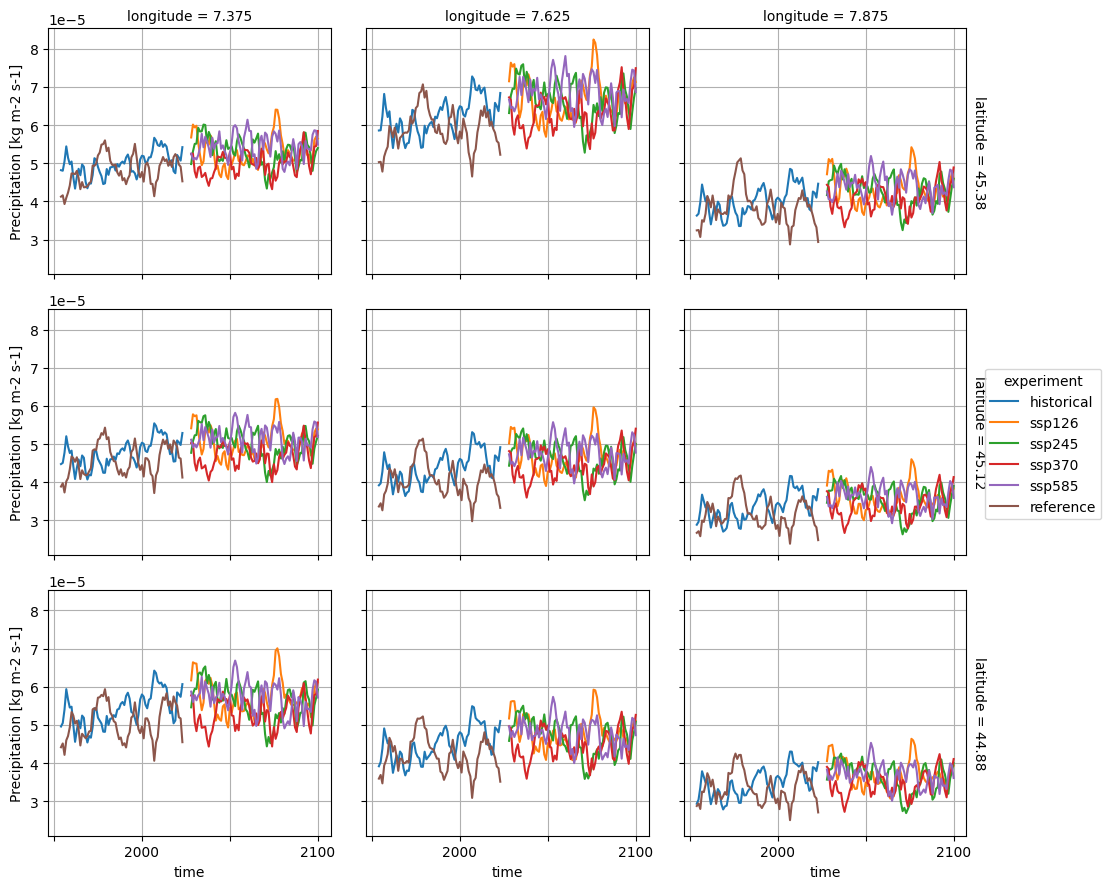

In [12]:
for v in variables:
    plots.yearly_mean_time_series_facet(ds_adjusted[v], hue=e_dim, fname=f"adjusted_{v}_{m}_post.pdf")

Compare pre and post BA time series qualitatively.

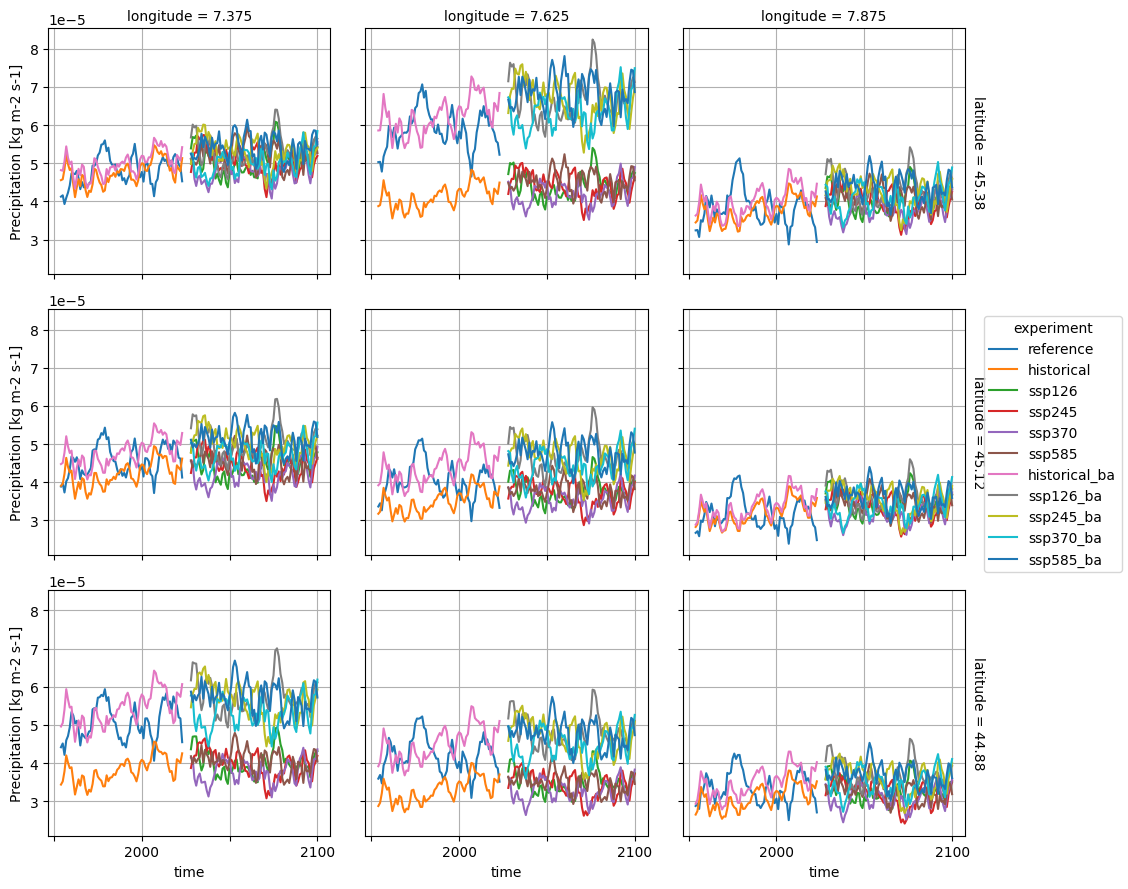

In [13]:
_ds = xarray.concat(
    (ds_data[variables], ds_adjusted[variables].assign_coords({e_dim: ds_adjusted[e_dim].str + "_ba"})),
    e_dim,
    combine_attrs="drop_conflicts"
)
_ds = _ds.drop_sel({e_dim: "reference_ba"})  # Do not plot same time series twice.
for v in variables:
    plots.yearly_mean_time_series_facet(_ds[v], hue=e_dim, fname=f"adjusted_{v}_{m}_prepost.pdf")

## Test BA

Use a period of the historical experiment to show qualitatively the performance of the BA.

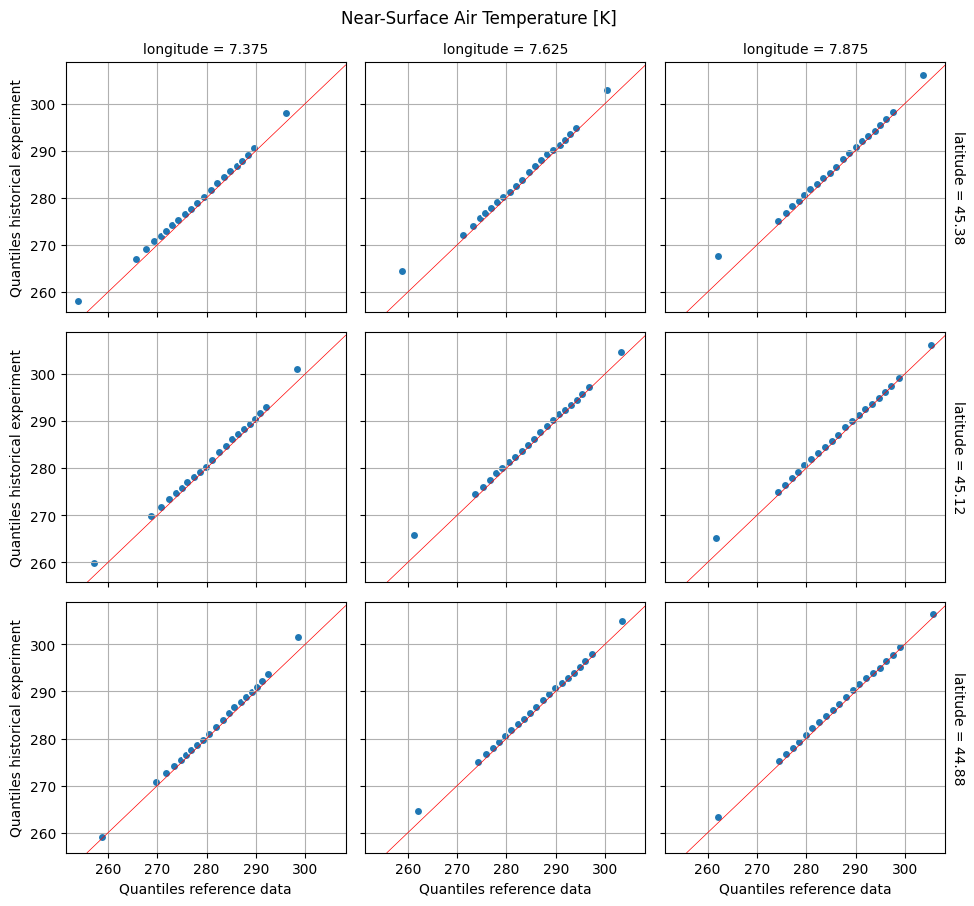

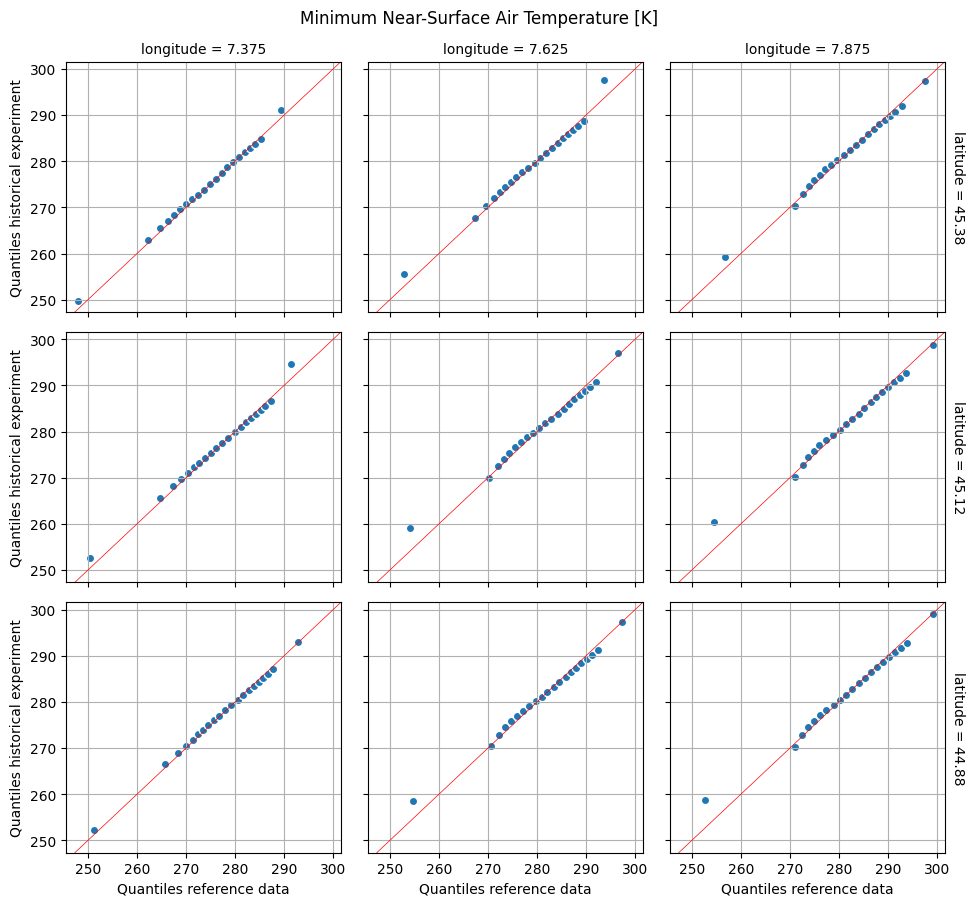

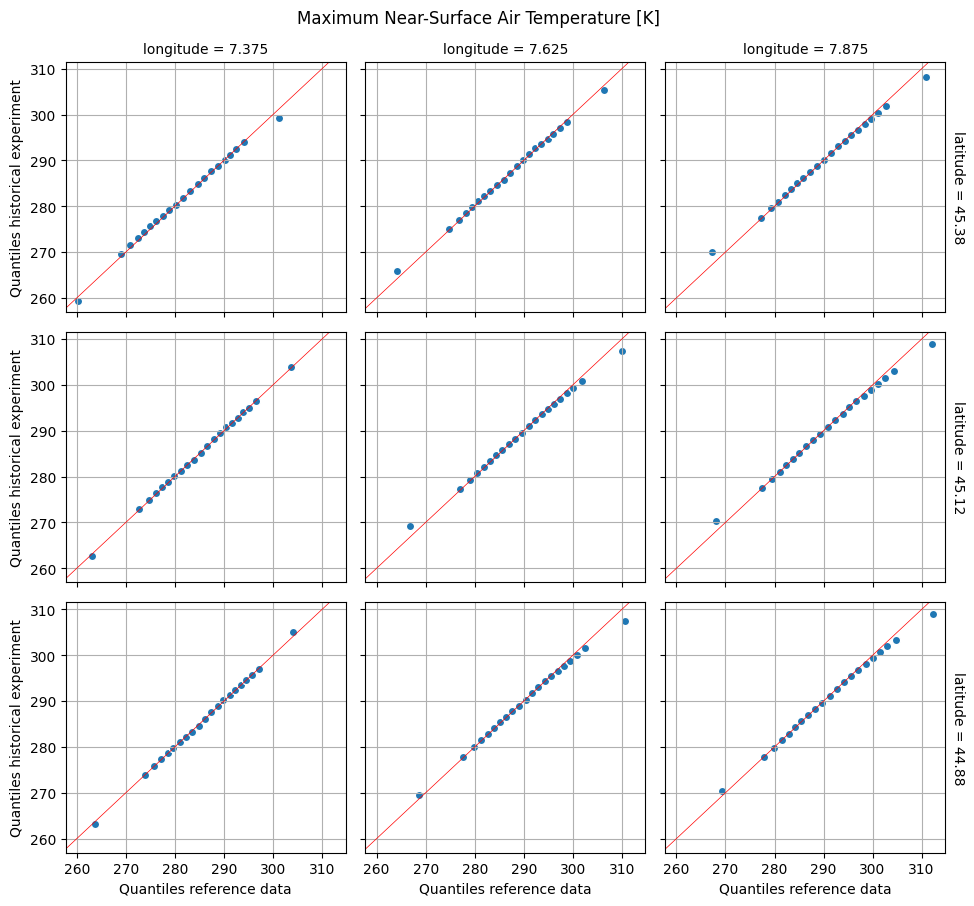

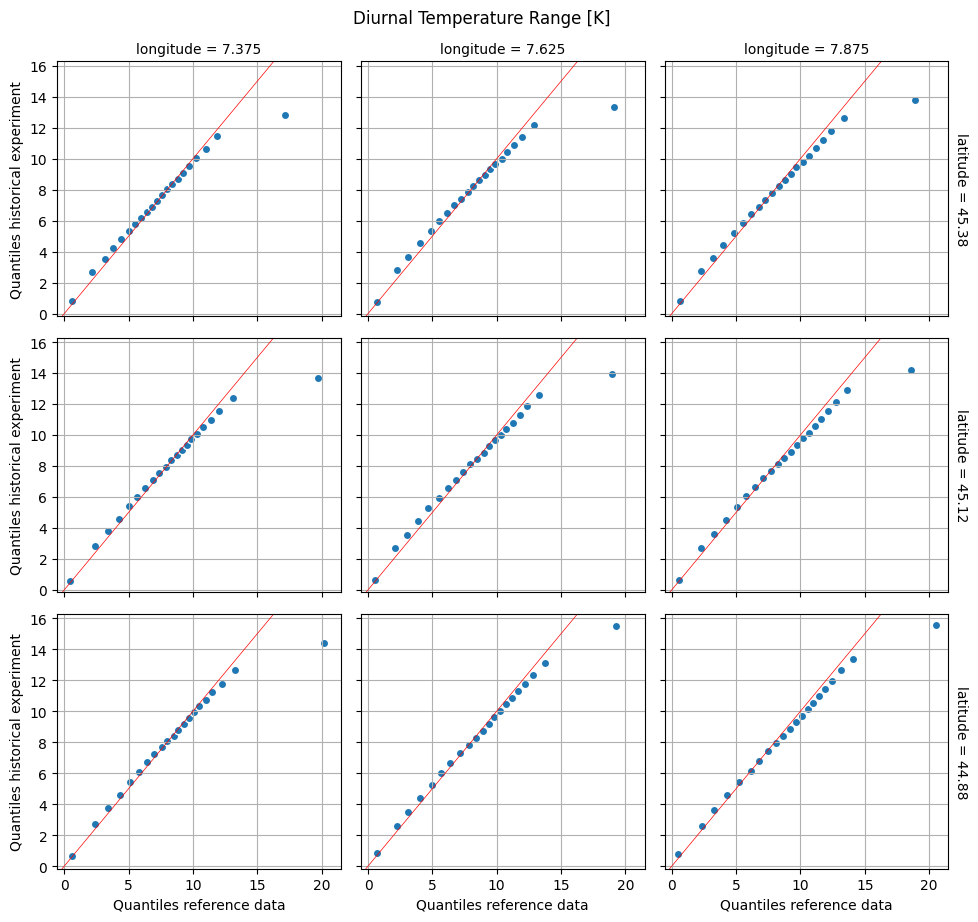

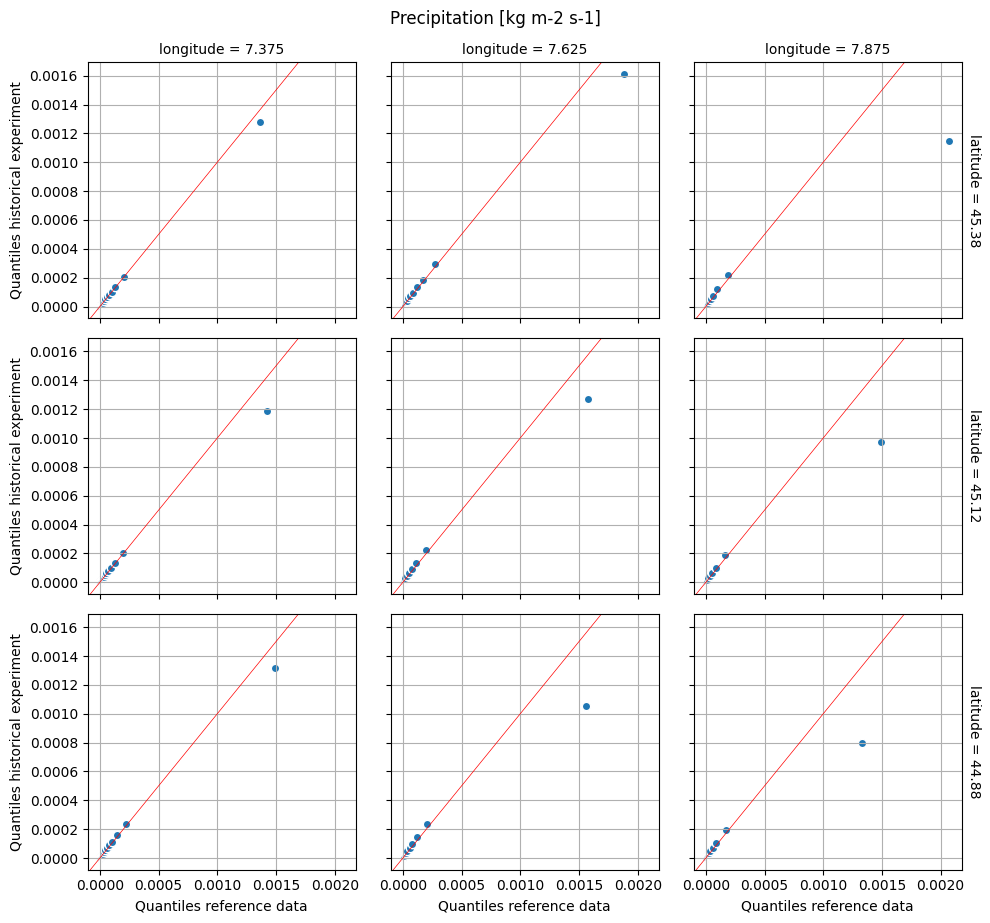

In [14]:
quantiles = numpy.linspace(0, 1, num=nquantiles_test, endpoint=True)

_reference = ds_data.sel({e_dim: "reference", "time": thesis.test_period}).quantile(quantiles, dim="time")
_historical = ds_adjusted.sel({e_dim: "historical", "time": thesis.test_period}).quantile(quantiles, dim="time")
_ds = _historical.assign({f"{k}_th": v for k, v in _reference.data_vars.items()})  # Distinguish theoretical quantiles.

for v in ba.keys():
    _plot = plots.scatter_facet(_ds, x=f"{v}_th", y=v)
    _plot.fig.suptitle(f"{_ds[v].attrs['long_name']} [{_ds[v].attrs['units']}]", y=1, verticalalignment="bottom")
    _plot.set_axis_labels("Quantiles reference data", "Quantiles historical experiment")
    for ax in _plot.axs.ravel():
        ax.axline((0,0), slope=1, color="red", linewidth=0.5)
    plots.savefig(f"adjusted_{v}_{m}_test.pdf")

Store the adjusted data in a file for future use.

In [15]:
experiments = list(dict_dataset.keys())
experiments.remove("reference")
variables = list(ba.keys())
variables.remove("DTR")

for e in experiments:
    ds_adjusted[variables].sel({e_dim: e}, drop=True).to_netcdf(dir_out / f"{e}_{m}.nc")

In [ ]:
# Release memory resources.
plt.close("all")